# MonReader — 05 Final Analysis and Interpretation

> **Authority status:** `HISTORICAL_NON_AUTHORITATIVE_PRE_V2`  
> This notebook is the submission-ready synthesis of the completed historical analysis. It does not modify the current V2 protocol.

## What this notebook does

- consolidates frozen performance and source-video uncertainty;
- compares Scratch CNN and ResNet18 descriptively;
- summarizes failure modes;
- displays deterministic Grad-CAM heatmaps;
- summarizes fixed-layer activation maps;
- records final conclusions and limitations.

No training, tuning, checkpoint replacement, case reselection, or new model selection is performed.

In [ ]:
from pathlib import Path
import sys

# Portable repository discovery: no machine-specific paths.
HERE = Path.cwd().resolve()
REPO_ROOT = next(
    (
        p for p in [HERE, *HERE.parents]
        if (p / "submission" / "results").is_dir()
    ),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError(
        "Run this notebook from inside a clone of the MonReader repository."
    )

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from submission.src.repro import load_snapshot, figures_dir, data_root

print(f"Repository root: {REPO_ROOT}")
print(f"Optional local data root: {data_root() or 'not configured (report mode is still available)'}")


## Final historical ResNet18 performance

| regime   |   n_samples |   n_source_videos |   notflip_f1 |   flip_f1 |   macro_f1 |   macro_f1_ci_lower |   macro_f1_ci_upper |   balanced_accuracy |   roc_auc_flip |   pr_auc_flip |      mcc |   macro_f1_delta_vs_O |
|:---------|------------:|------------------:|-------------:|----------:|-----------:|--------------------:|--------------------:|--------------------:|---------------:|--------------:|---------:|----------------------:|
| O        |         597 |               115 |     0.995138 |  0.994801 |   0.994969 |            0.986128 |            1        |            0.994828 |       0.999966 |      0.999965 | 0.989989 |              0        |
| S        |         610 |                24 |     0.963504 |  0.953271 |   0.958387 |            0.909802 |            0.993352 |            0.958202 |       0.989608 |      0.989565 | 0.91678  |             -0.036582 |
| T        |         301 |               117 |     0.919403 |  0.898876 |   0.90914  |            0.865657 |            0.946739 |            0.908163 |       0.987013 |      0.989595 | 0.833399 |             -0.08583  |
| ST       |         121 |                24 |     0.906667 |  0.847826 |   0.877246 |            0.747988 |            0.972281 |            0.867925 |       0.919673 |      0.923687 | 0.781163 |             -0.117723 |

The historical robustness gradient is clear: Macro F1 decreases from approximately **0.995 (O)** to **0.958 (S)**, **0.909 (T)**, and **0.877 (ST)**. ST also carries the broadest source-video confidence interval.

## Final error summary

| regime   |   total_errors |   error_rate |   fp |   fn | dominant_error_type   |   mean_error_confidence |   high_confidence_error_share_ge_0_90 |
|:---------|---------------:|-------------:|-----:|-----:|:----------------------|------------------------:|--------------------------------------:|
| O        |              3 |     0.005025 |    0 |    3 | false_negative        |                0.782592 |                              0.333333 |
| S        |             25 |     0.040984 |   12 |   13 | false_negative        |                0.806825 |                              0.32     |
| T        |             27 |     0.089701 |    0 |   27 | false_negative        |                0.870143 |                              0.518519 |
| ST       |             14 |     0.115702 |    0 |   14 | false_negative        |                0.948652 |                              0.785714 |

False negatives are the dominant error mode. The share of errors made with confidence ≥ 0.90 increases materially in T and ST, so the harder regimes contain genuinely confident failures rather than only borderline threshold cases.

## Final report figures

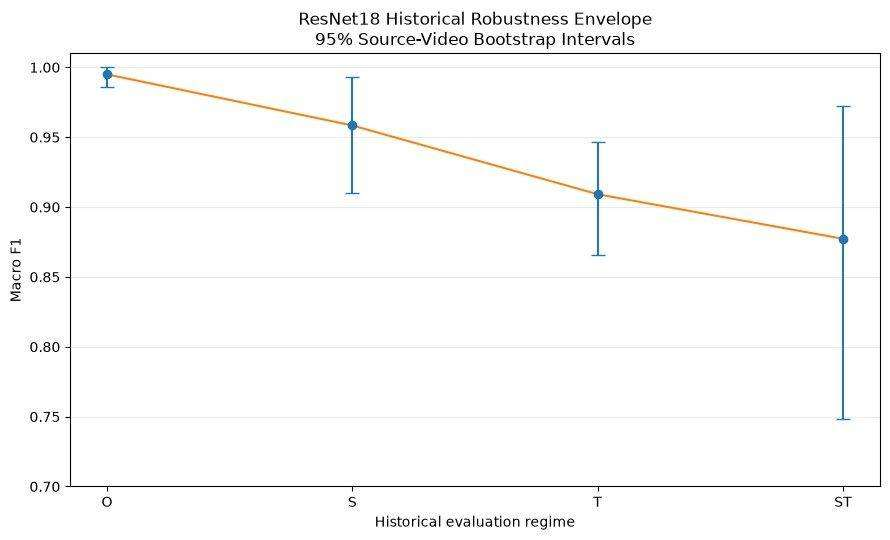

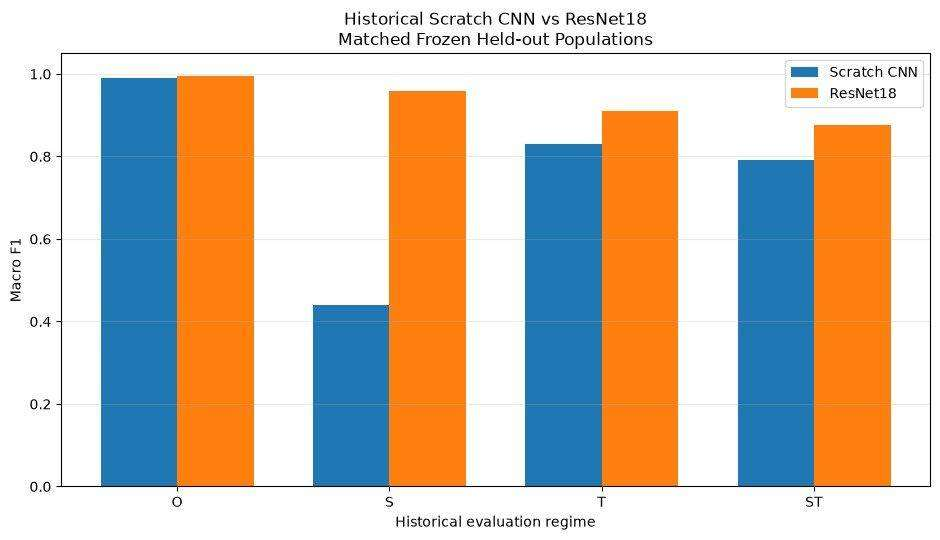

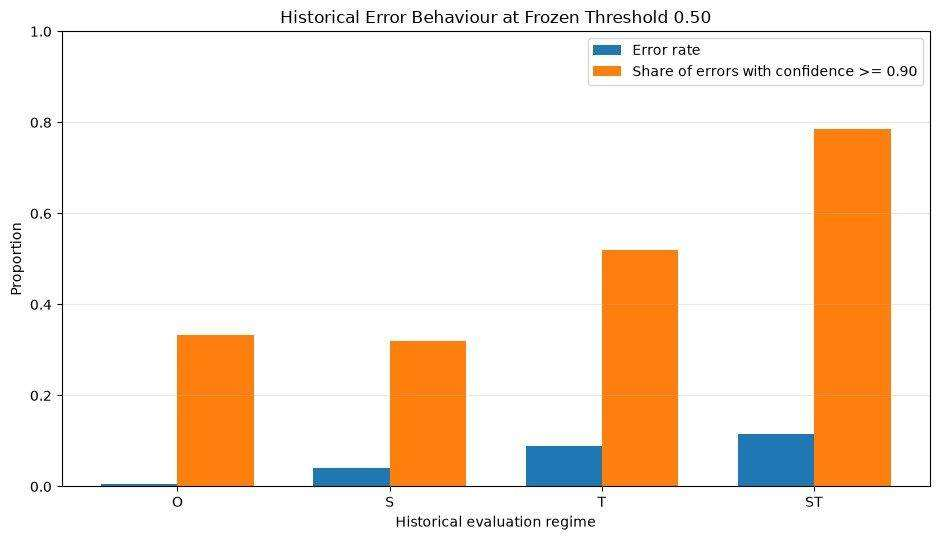

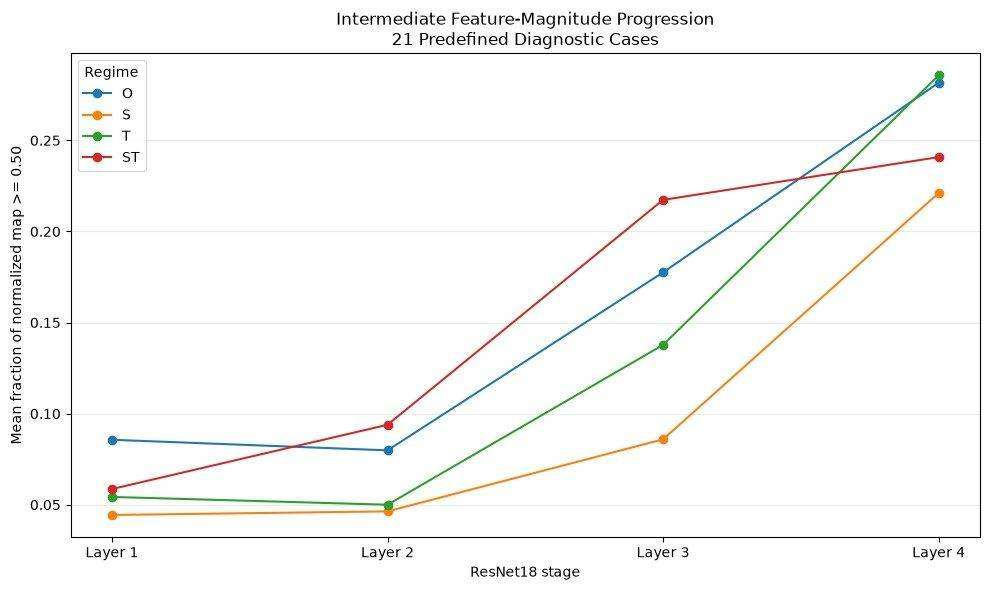

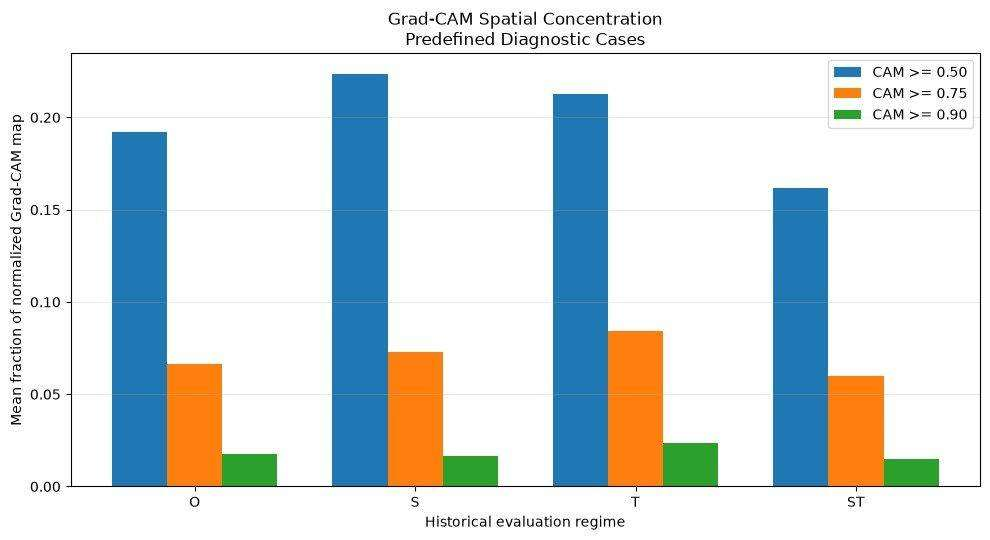


# Grad-CAM heatmaps

These are the actual frozen Grad-CAM regime panels generated from the 21 deterministic interpretability cases. The cases were fixed before visual inspection; no heatmap was used to alter a checkpoint, threshold, or sample registry.

## O

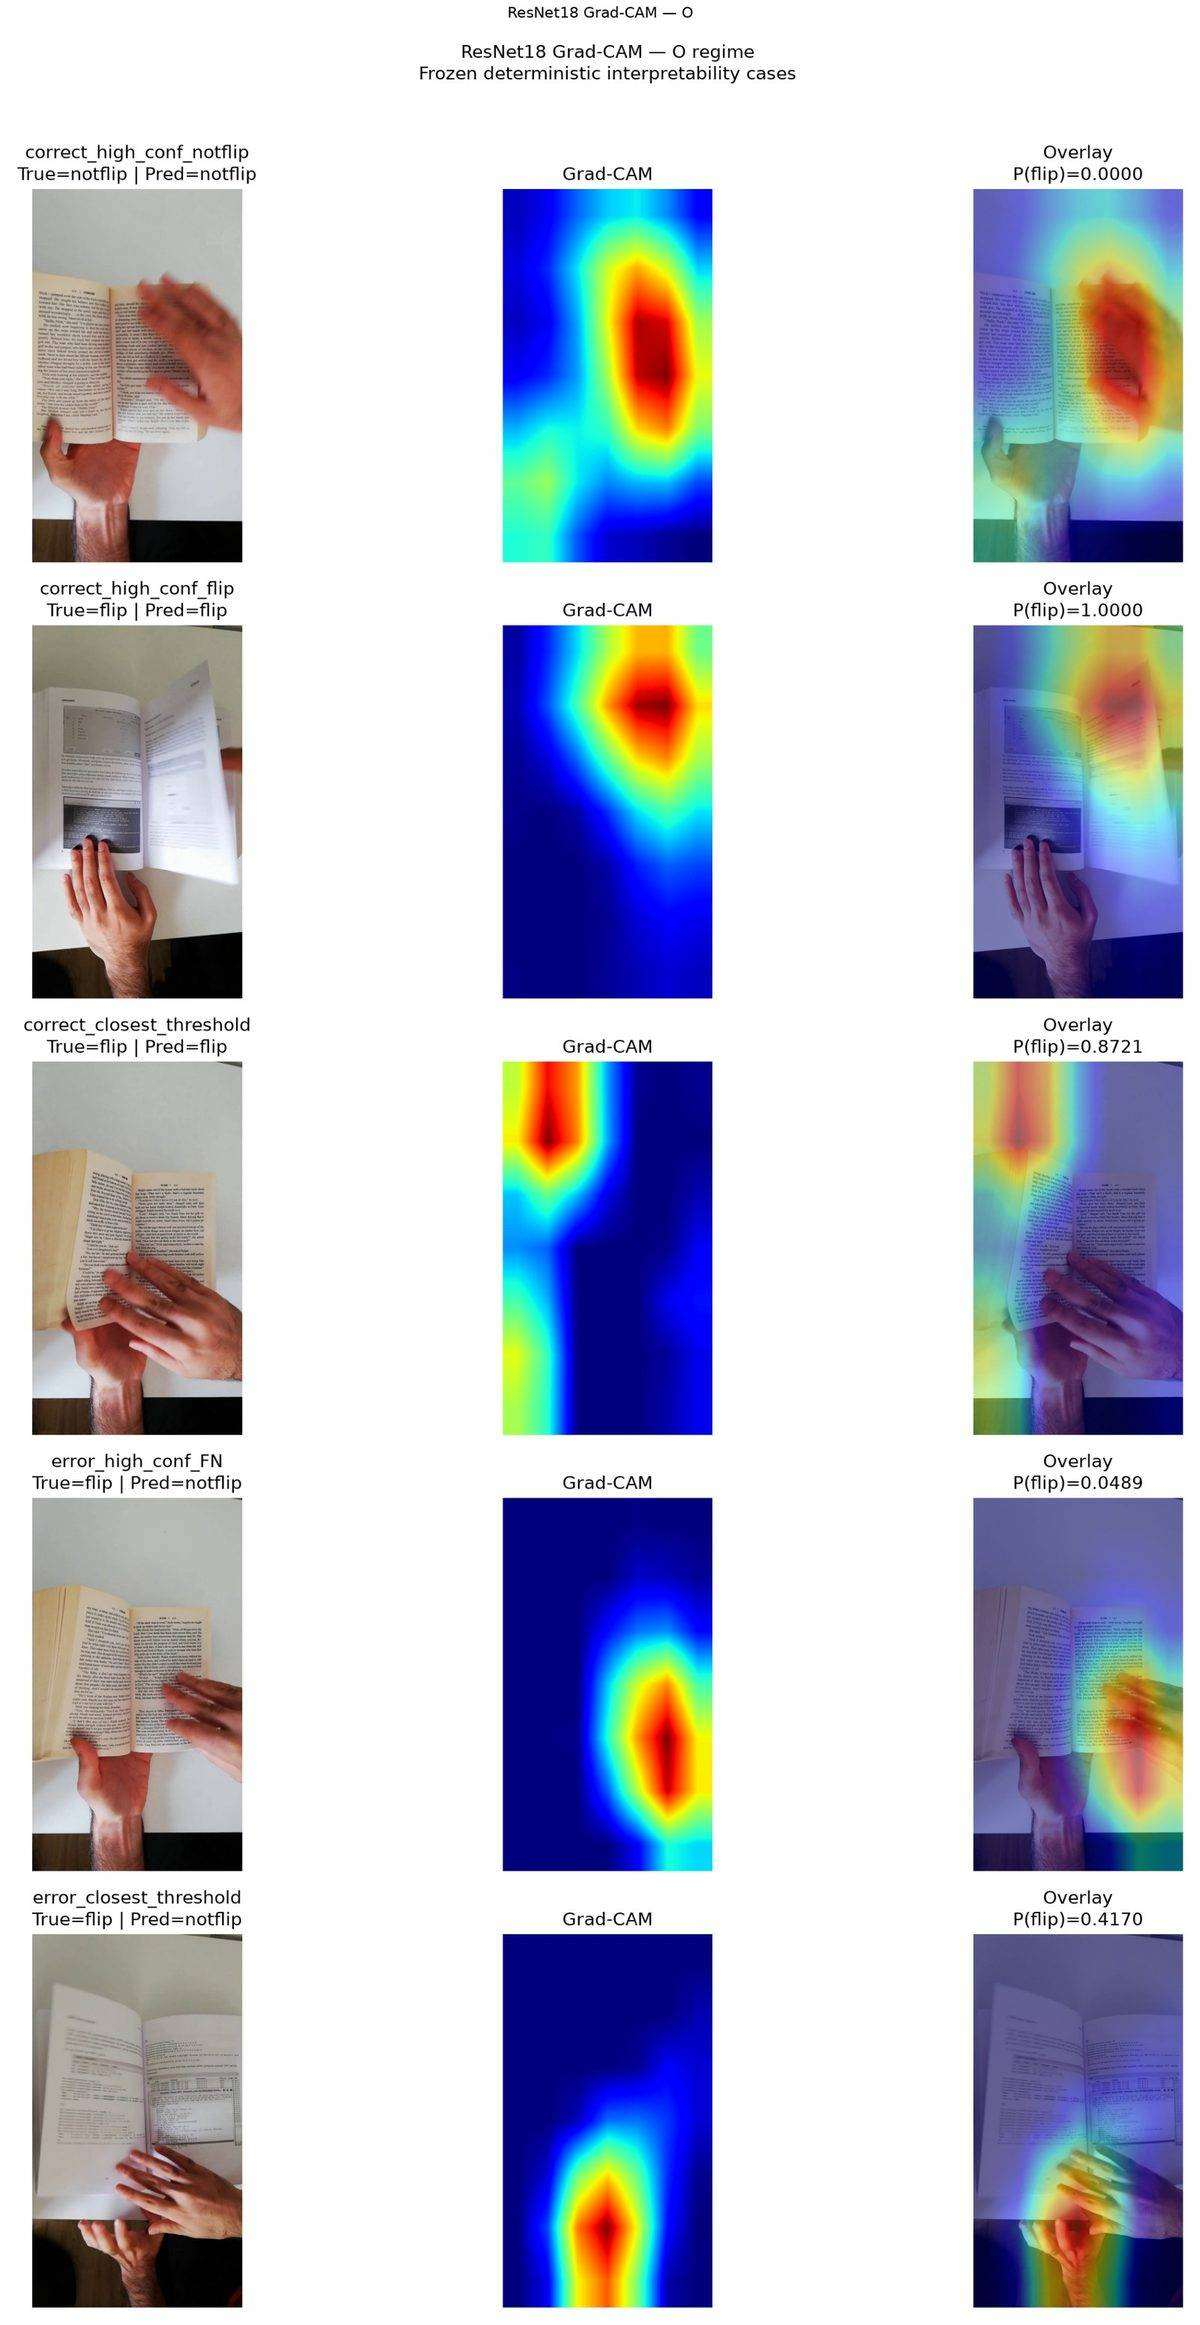

## S

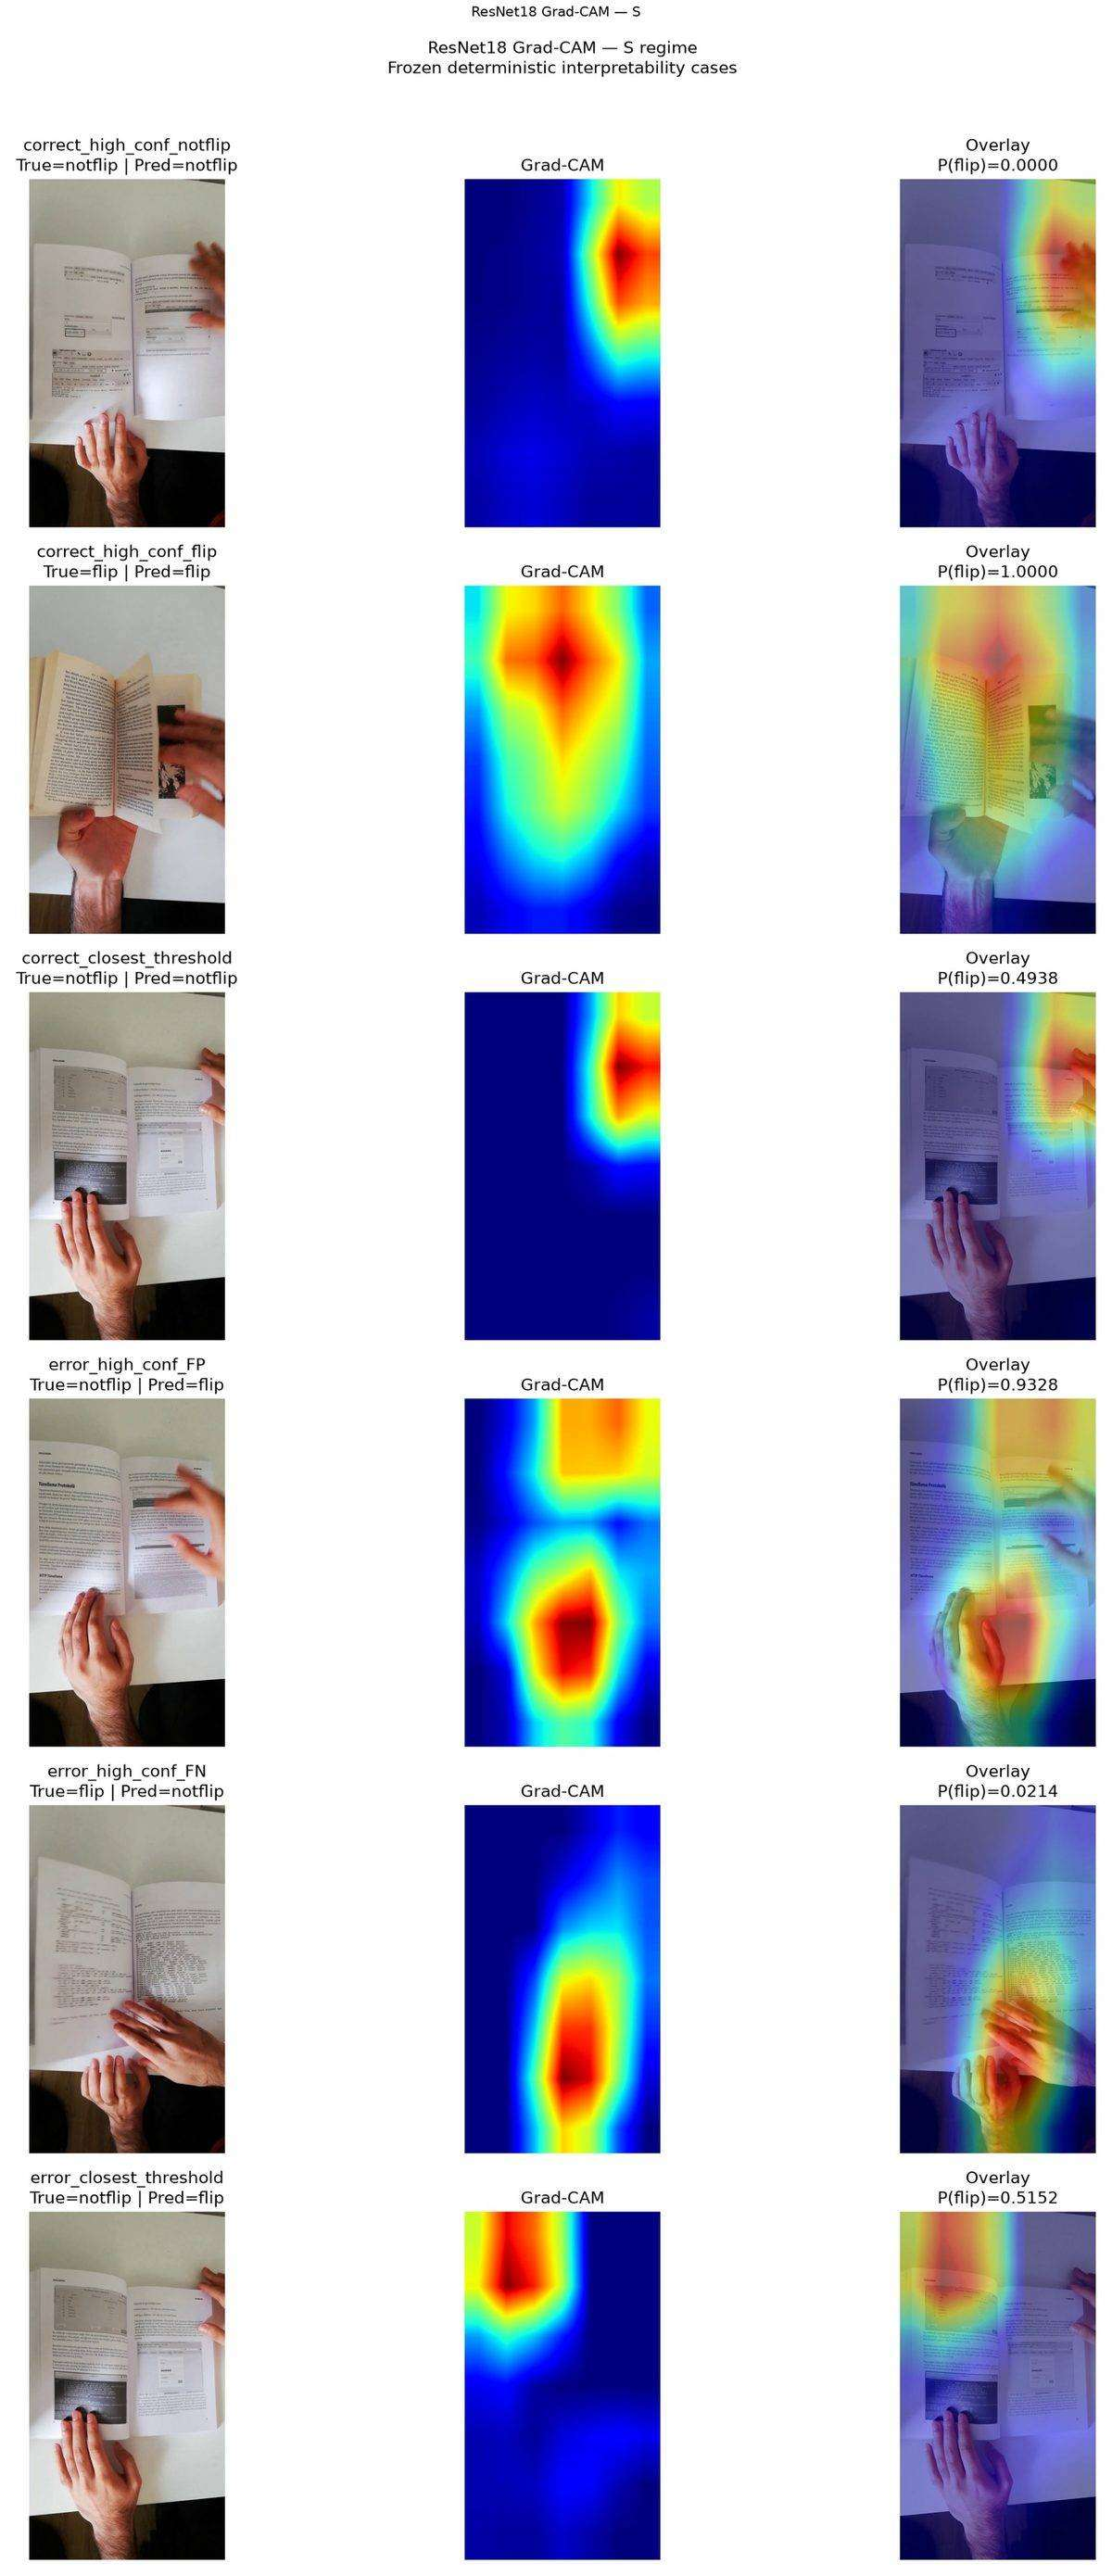

## T

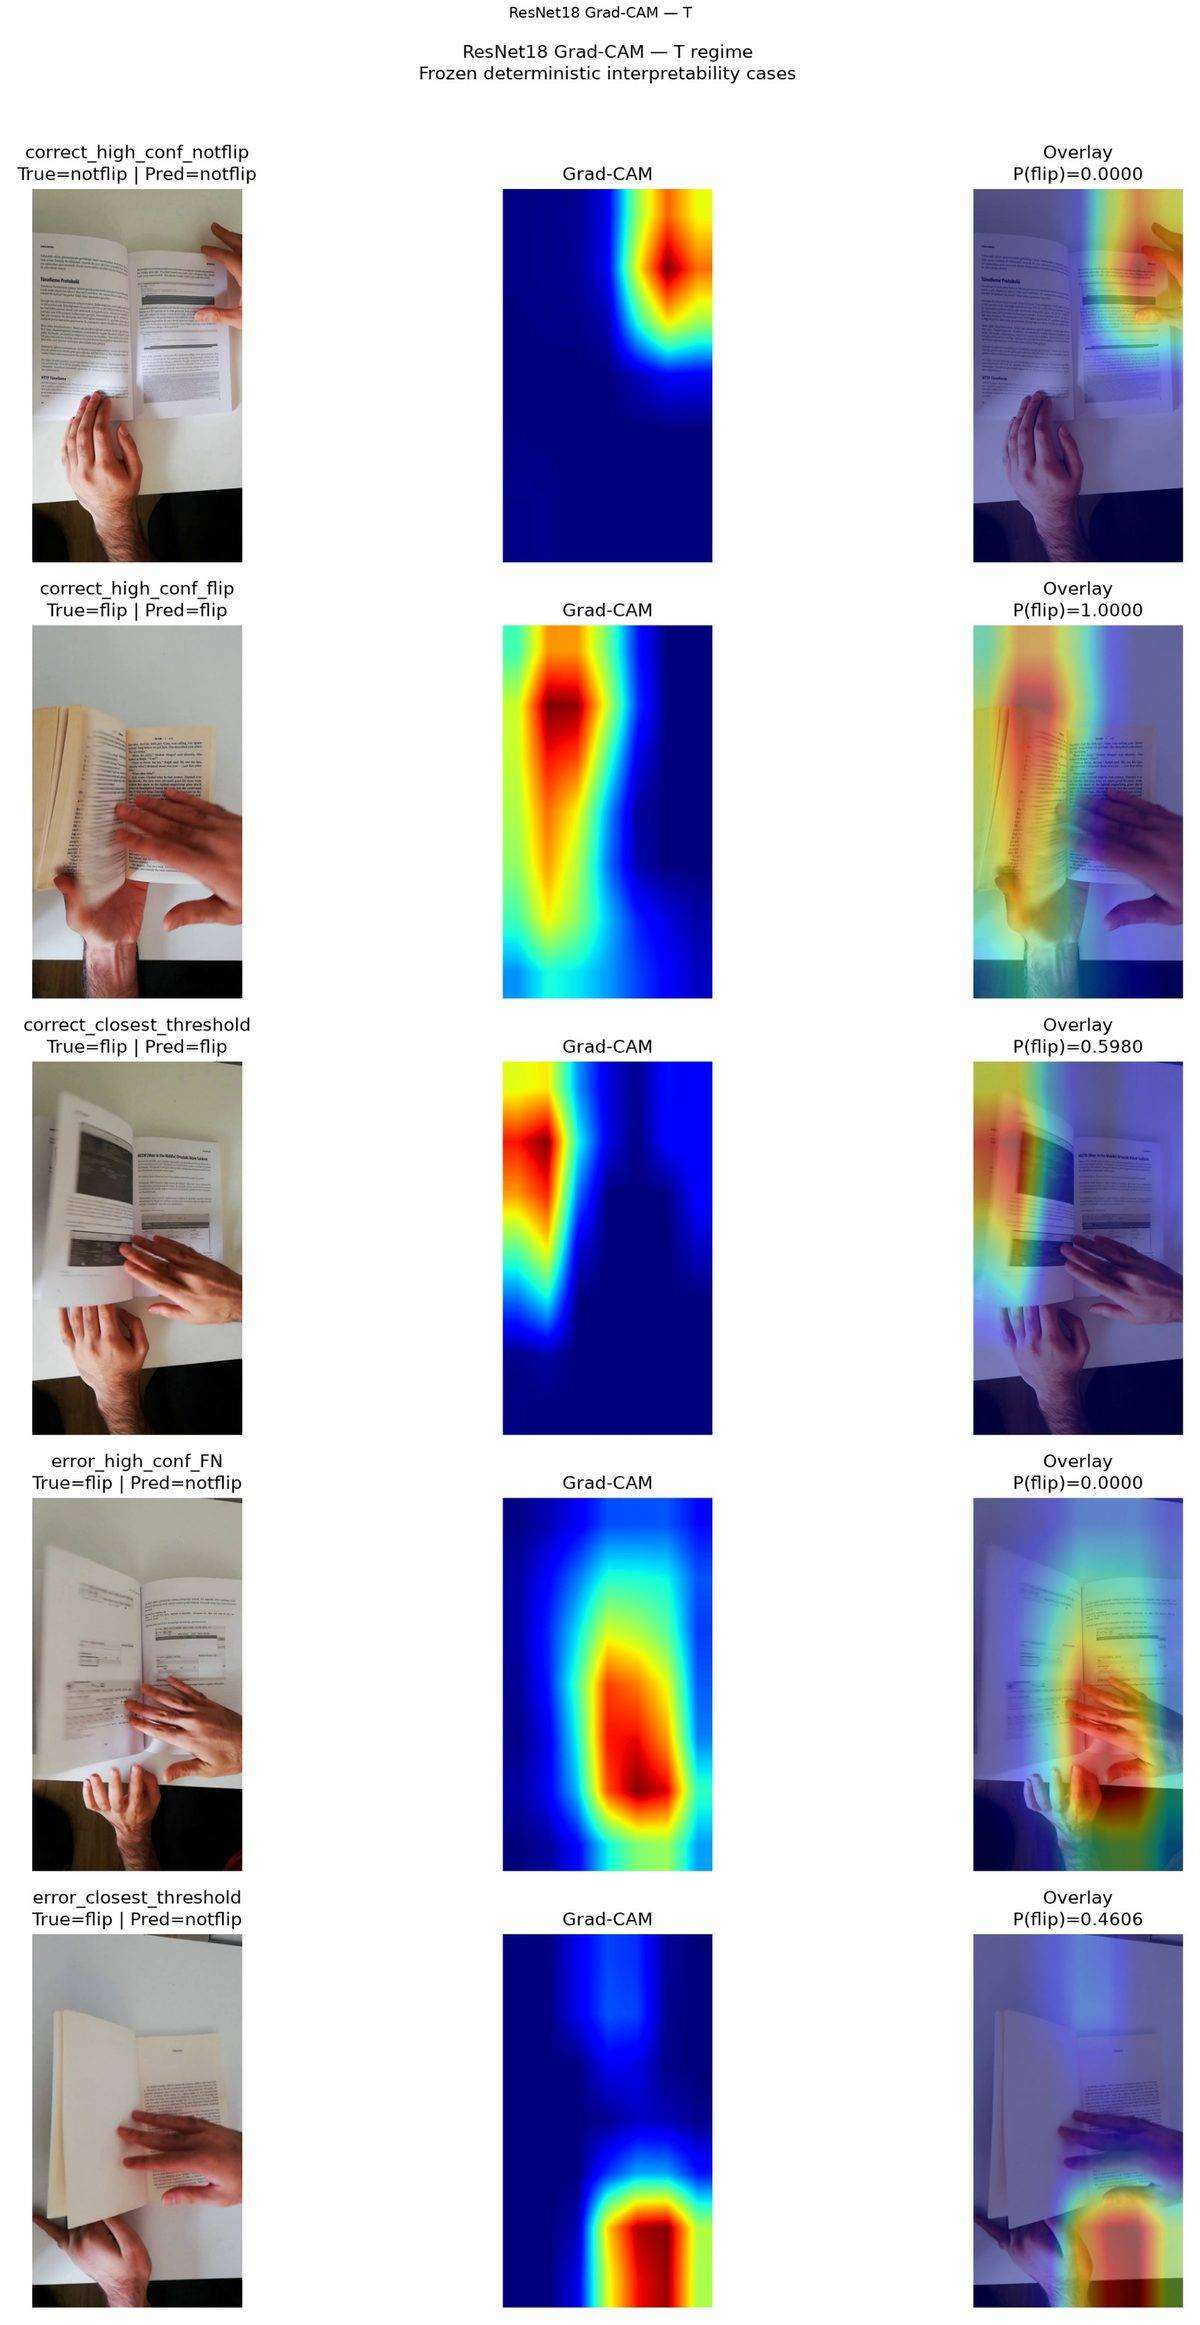

## ST

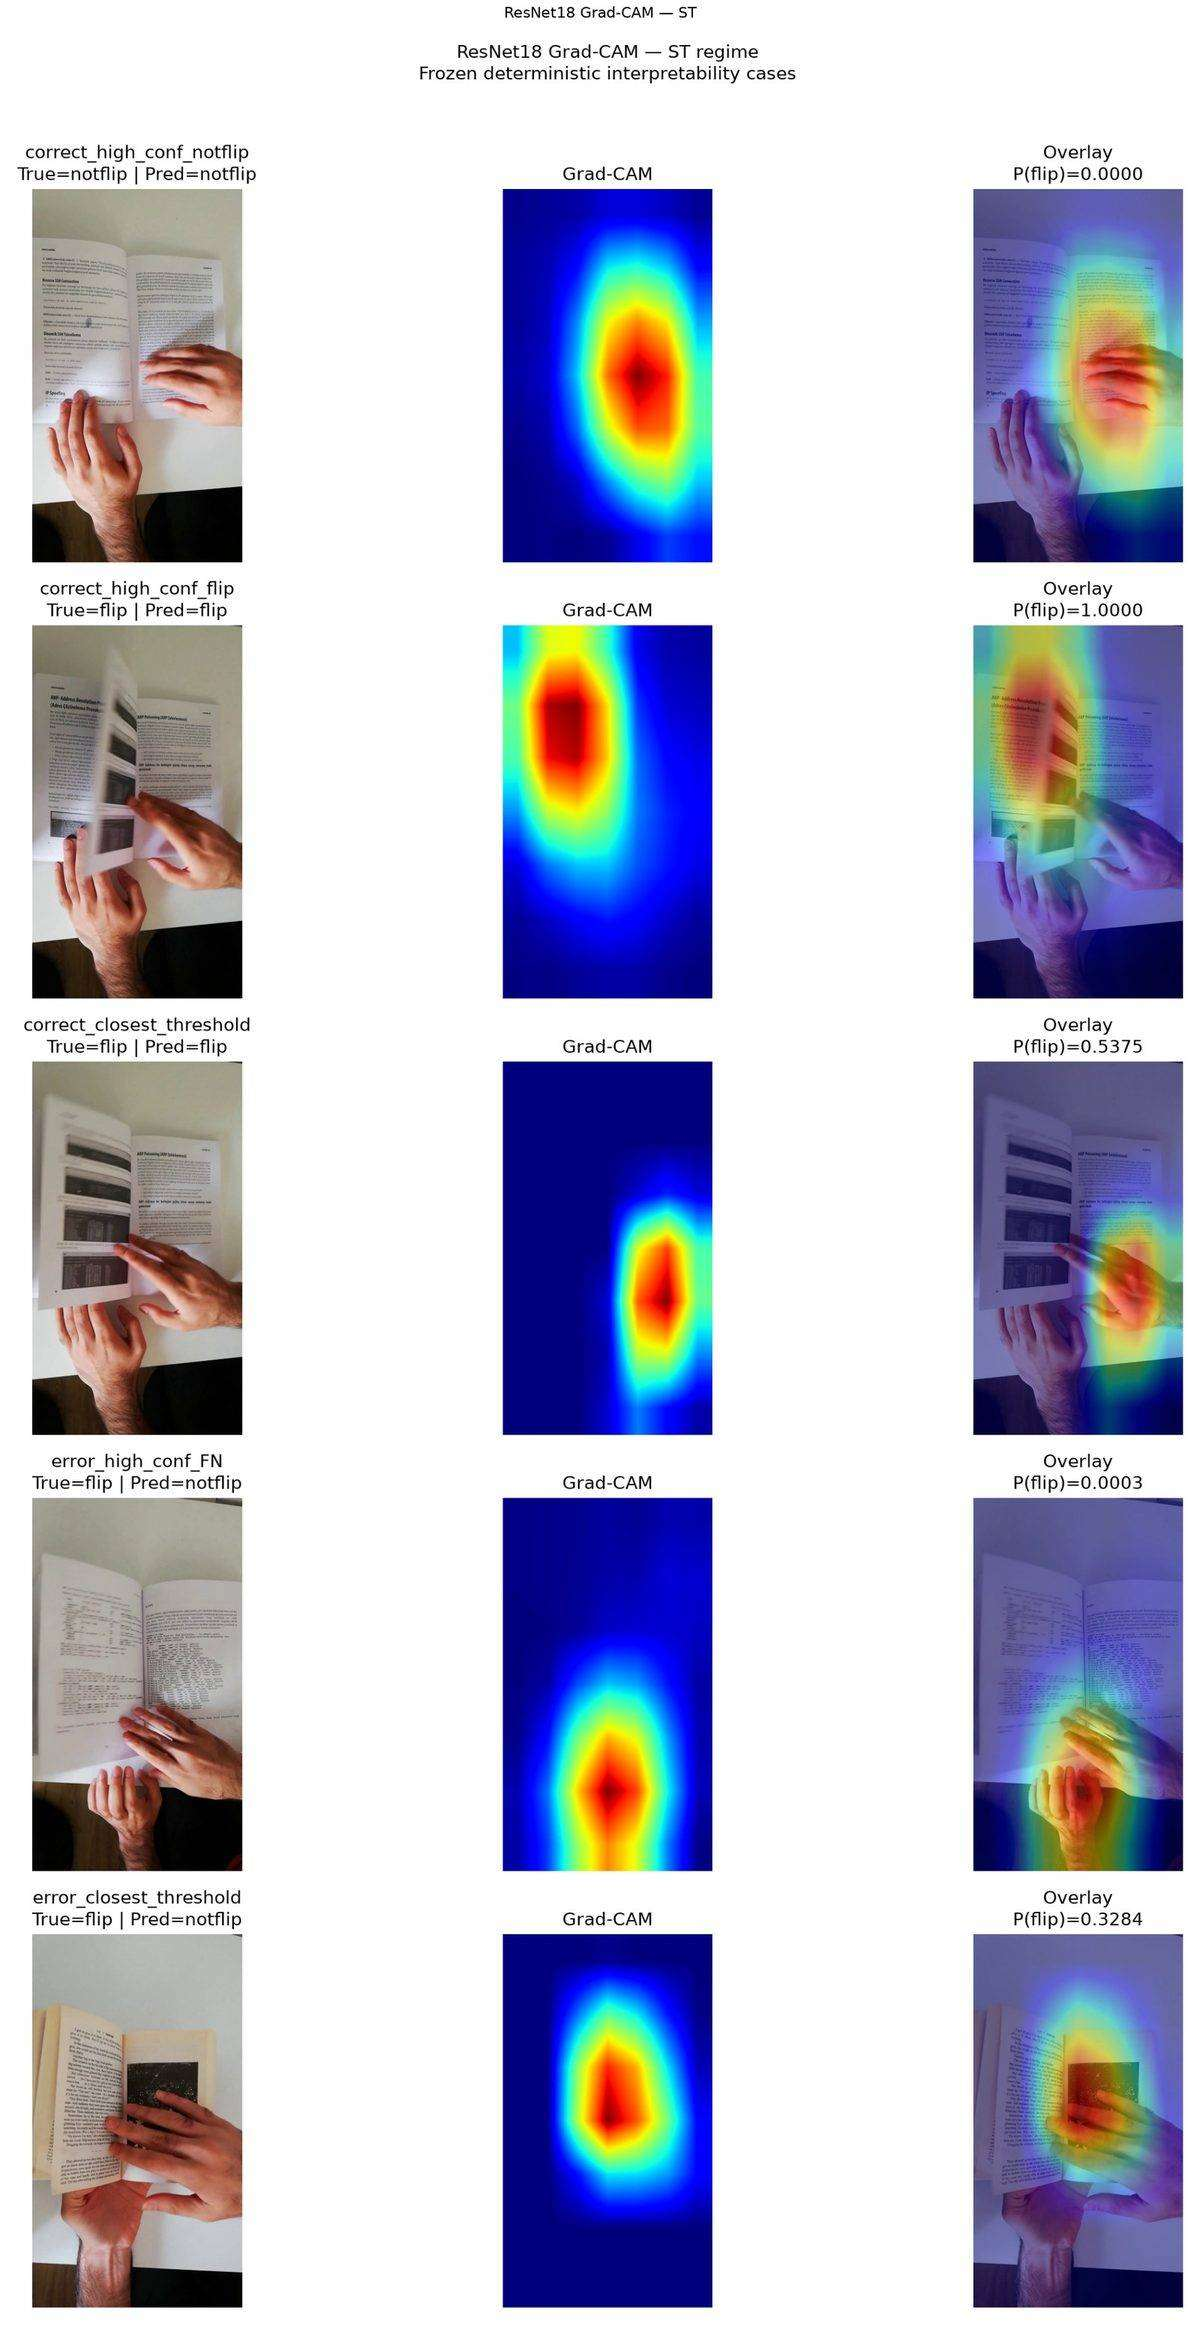

> Grad-CAM is diagnostic and associative. It does **not** prove causal feature importance.

## Grad-CAM numerical audit

| regime   |   n_cases |   n_degenerate_cam |   mean_cam_activation |   mean_fraction_cam_ge_0_50 |   mean_fraction_cam_ge_0_75 |   mean_fraction_cam_ge_0_90 | all_predictions_match   |
|:---------|----------:|-------------------:|----------------------:|----------------------------:|----------------------------:|----------------------------:|:------------------------|
| O        |         5 |                  0 |              0.237532 |                    0.192136 |                    0.066554 |                    0.01775  | True                    |
| S        |         6 |                  0 |              0.251104 |                    0.223533 |                    0.072734 |                    0.016273 | True                    |
| T        |         5 |                  0 |              0.235299 |                    0.212819 |                    0.084343 |                    0.023374 | True                    |
| ST       |         5 |                  0 |              0.207746 |                    0.161691 |                    0.059893 |                    0.015039 | True                    |

## Intermediate activation summary

| regime   | layer      |   n_cases |   n_degenerate |   mean_normalized_activation |   mean_fraction_ge_0_50 |   mean_fraction_ge_0_75 |   mean_fraction_ge_0_90 | all_predictions_match   |
|:---------|:-----------|----------:|---------------:|-----------------------------:|------------------------:|------------------------:|------------------------:|:------------------------|
| O        | layer1[-1] |         5 |              0 |                     0.280094 |                0.085651 |                0.008546 |                0.001276 | True                    |
| O        | layer2[-1] |         5 |              0 |                     0.252207 |                0.079847 |                0.018367 |                0.004592 | True                    |
| O        | layer3[-1] |         5 |              0 |                     0.322155 |                0.177551 |                0.034694 |                0.017347 | True                    |
| O        | layer4[-1] |         5 |              0 |                     0.363313 |                0.281633 |                0.114286 |                0.04898  | True                    |
| S        | layer1[-1] |         6 |              0 |                     0.227997 |                0.044377 |                0.004517 |                0.00085  | True                    |
| S        | layer2[-1] |         6 |              0 |                     0.21768  |                0.046344 |                0.006378 |                0.002976 | True                    |
| S        | layer3[-1] |         6 |              0 |                     0.259192 |                0.085884 |                0.016156 |                0.006803 | True                    |
| S        | layer4[-1] |         6 |              0 |                     0.305392 |                0.221088 |                0.081633 |                0.02381  | True                    |
| T        | layer1[-1] |         5 |              0 |                     0.240703 |                0.054273 |                0.005357 |                0.000702 | True                    |
| T        | layer2[-1] |         5 |              0 |                     0.221548 |                0.05     |                0.008418 |                0.002296 | True                    |
| T        | layer3[-1] |         5 |              0 |                     0.298294 |                0.137755 |                0.028571 |                0.011224 | True                    |
| T        | layer4[-1] |         5 |              0 |                     0.316527 |                0.285714 |                0.093878 |                0.040816 | True                    |
| ST       | layer1[-1] |         5 |              0 |                     0.247629 |                0.05861  |                0.00523  |                0.000638 | True                    |
| ST       | layer2[-1] |         5 |              0 |                     0.279457 |                0.093878 |                0.015306 |                0.002041 | True                    |
| ST       | layer3[-1] |         5 |              0 |                     0.348398 |                0.217347 |                0.043878 |                0.013265 | True                    |
| ST       | layer4[-1] |         5 |              0 |                     0.290347 |                0.240816 |                0.097959 |                0.032653 | True                    |

The four fixed stages progress from `56×56` to `28×28` to `14×14` to `7×7` spatial maps. Mean absolute activation is class-agnostic and is shown only as a diagnostic of representation progression; individual bright regions should not be assigned semantic meaning.

## Final scientific interpretation

1. **Nominal performance is not the whole story.** O is near ceiling, but stress regimes are materially harder.
2. **Source-video separation matters.** S is still strong for historical ResNet18, but it is not proof of universal environment generalization.
3. **Temporal stress matters.** T is clearly weaker than O.
4. **Combined stress is hardest.** ST has the lowest point Macro F1 and widest source-video uncertainty.
5. **Pretraining helped historically.** ResNet18 exceeded the frozen Scratch CNN reference on all four matched historical populations, especially S.
6. **Failure asymmetry matters.** False negatives dominate and many T/ST failures are highly confident.
7. **Interpretability remains diagnostic.** Grad-CAM and activation maps contextualize model behaviour but do not establish causality.
8. **The historical RGB/grayscale branch is closed.** It did not satisfy the full meaningful-effect gate.


## Limitations

- O/S/T/ST are different frozen populations; cross-regime deltas are descriptive, not isolated causal effects.
- Frames within a source video are correlated; source-video bootstrap is therefore primary.
- ST has only 24 source videos and 121 held-out frames, giving substantially wider uncertainty.
- The 21 interpretability cases are deterministic representative cases, not a population-frequency sample.
- Grad-CAM is not a causal explanation.
- These notebooks are **historical pre-V2** and must not overwrite current V2 results.


## Final conclusion

Within the historical workflow, the strongest methodological lesson is that **MonReader must be evaluated with source-aware and temporally aware splits rather than relying on nominal held-out performance alone**.

The nominal O result demonstrates what the classifier can achieve under favourable historical conditions. S, T, and ST expose robustness limits, wider uncertainty, and failure modes that O alone would hide.

For the current project, these results remain a documented reproducibility record. Any result used to support the authoritative V2 analysis must be produced under V2 itself.